# S10 - Series de tiempo e inferencia en streaming

**Proyecto Sello — Equipo LLSW3.** Se construye lo que S04 dejó pendiente: un modelo que predice `CE` del **segundo siguiente** a partir de la lectura actual, entrenado sobre el Gold de S04 (`campo_electrico_particionado`) y aplicado en vivo sobre el topic Kafka `campo-electrico-eventos`.

**Coherencia entre histórico y streaming.** El histórico de S04 (100 000 lecturas, una por segundo) y el productor Kafka usan el **mismo** módulo `uso-campo-electrico/app/simulador_campo_electrico.py`: mismos rangos, mismo paso máximo, misma dinámica de `CE` y el mismo intervalo de **1 s**. Por eso `t+1` significa lo mismo en el entrenamiento (fila siguiente del Gold) y en producción (la próxima lectura del productor, un segundo después).

```text
Gold S04 (1 lectura/s) ─► label = lead(CE,1) ─► división 80/20 cronológica
        ├─► baseline de persistencia (CE_t+1 = CE_t)
        └─► LinearRegression vs RandomForestRegressor ─► comparar vs baseline ─► PipelineModel
producer_campo_electrico.py (1 lectura/s) ─► Kafka ─► readStream ─► PipelineModel.transform ─► foreachBatch ─► Parquet
```

## 3.1 Fase 1 — Business Understanding

### 3.1.1 `SparkSession` (con el conector de Kafka desde el inicio)

In [1]:
from pyspark.sql import SparkSession
spark = (
    SparkSession.builder
    .appName("sesion10-series-tiempo-inferencia")
    .master("local[*]")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.session.timeZone", "America/Lima")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
import datetime
print("Spark", spark.version, "| ejecutado:", datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=-5))).strftime("%Y-%m-%d %H:%M:%S"), "(Lima)")

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-358bd2eb-47e9-4dd8-86f9-aa1b34b741a7;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central


	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.modules#scala-parallel-collections_2.13;1.2.0 in central
	found org.apache.commons#commons-pool2;2.13.1 in central
:: resolution report :: resolve 200ms :: artifacts dl 9ms
	:: modules in use:
	at.yawk.lz4#lz4-java;1.11.0 from central in [default]
	com.google.code.findbugs#jsr305;3.0.0 from central in [default]
	org.apache.commons#commons-pool2;2.13.1 from central in [default]
	org.apache.hadoop#hadoop-client-api;3.5.0 from central in [default]
	org.apache.hadoop#hadoop-client-runtime;3.5.0 from central in [default]
	org.apache.kafka#kafka-clients;3.9.2 from central in [default]
	org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 from central in [default]
	org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 from central in [default]
	org.scala-lang.modules#scala-parallel-collection

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.2.0 | ejecutado: 2026-10-21 09:57:12 (Lima)


### 3.1.2 Objetivo y alcance

**Objetivo:** estimar `CE` en el segundo siguiente (`CE_t+1`) a partir de las 8 variables físicas de la lectura actual, reutilizando el Gold de S04.

**Alcance:** comparar un **baseline de persistencia**, una **regresión lineal** y un **Random Forest**, con división **cronológica**, reportando RMSE/MAE/R² contra el baseline; guardar el ganador como `PipelineModel` y aplicarlo en tiempo real sobre Kafka, una lectura a la vez, sin ventanas ni estado.

## 3.2 Fase 2 — Data Understanding

### 3.2.1 Cargar el Gold de S04

In [2]:
RUTA_GOLD_S04 = "/opt/artifacts/s04/campo_electrico_particionado"
VARIABLES_8 = ["CE", "CM", "TempOut", "OutHum", "WindSpeed", "Bar", "SolarRad", "UVIndex"]
df_gold = spark.read.parquet(RUTA_GOLD_S04)
print(f"Filas del Gold de S04: {df_gold.count():,}")
df_gold.orderBy("DateTime").show(5)
df_gold.describe(VARIABLES_8).show()

Filas del Gold de S04: 99,820


+-------------------+-----+--------+-------+------+---------+------+--------+-------+----------+
|           DateTime|   CE|      CM|TempOut|OutHum|WindSpeed|   Bar|SolarRad|UVIndex|     Fecha|
+-------------------+-----+--------+-------+------+---------+------+--------+-------+----------+
|2026-10-19 00:00:00|-2.19|24031.04|  15.99| 68.12|     13.2|951.02|  681.17|   0.43|2026-10-19|
|2026-10-19 00:00:01|-2.21|24029.66|  16.05| 67.75|    13.12|950.95|  687.72|   0.38|2026-10-19|
|2026-10-19 00:00:02|-2.14|24028.76|  16.11| 68.05|    13.04|950.95|  684.08|   0.28|2026-10-19|
|2026-10-19 00:00:03| -2.1|24030.09|   16.2| 67.89|    13.26|951.01|  683.57|   0.15|2026-10-19|
|2026-10-19 00:00:04|-2.12|24029.27|  16.24| 68.03|     13.2|951.08|  684.49|   0.03|2026-10-19|
+-------------------+-----+--------+-------+------+---------+------+--------+-------+----------+
only showing top 5 rows


+-------+-------------------+------------------+------------------+-----------------+-----------------+-----------------+------------------+------------------+
|summary|                 CE|                CM|           TempOut|           OutHum|        WindSpeed|              Bar|          SolarRad|           UVIndex|
+-------+-------------------+------------------+------------------+-----------------+-----------------+-----------------+------------------+------------------+
|  count|              99820|             99820|             99820|            99820|            99820|            99820|             99820|             99820|
|   mean|-1.6222925265477837|24138.232261971647| 21.90594800641137|77.97388759767625|9.232166399519159|949.4709995992808| 377.1389515127232|2.7697674814666593|
| stddev| 1.0201927148484116| 79.94082956441316|3.5095323713443753|8.501228091216351| 4.95576075210914|2.211249394308253|238.55323516662727|1.7439438864072851|
|    min|              -4.91|           

Es la misma salida con la que cerró S04: sin `CM = 99999`, sin nulos y sin `DateTime` duplicada. Hay una lectura por segundo; los 180 segundos con código de error de `CM` se descartaron en S04 y dejan pequeños huecos de 2 s en la serie.

## 3.3 Fase 3 — Data Preparation

### 3.3.1 Construir `label` con `lead("CE", 1)`

In [3]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
orden_temporal = Window.orderBy("DateTime")
dataset_ml = (
    df_gold
    .withColumn("label", F.lead("CE", 1).over(orden_temporal))
    .select("DateTime", *VARIABLES_8, "label")
    .na.drop()
)
print(f"Filas del Gold: {df_gold.count():,}")
print(f"Filas del dataset supervisado: {dataset_ml.count():,}")
dataset_ml.orderBy("DateTime").show(5)

Filas del Gold: 99,820


Filas del dataset supervisado: 99,819


+-------------------+-----+--------+-------+------+---------+------+--------+-------+-----+
|           DateTime|   CE|      CM|TempOut|OutHum|WindSpeed|   Bar|SolarRad|UVIndex|label|
+-------------------+-----+--------+-------+------+---------+------+--------+-------+-----+
|2026-10-19 00:00:00|-2.19|24031.04|  15.99| 68.12|     13.2|951.02|  681.17|   0.43|-2.21|
|2026-10-19 00:00:01|-2.21|24029.66|  16.05| 67.75|    13.12|950.95|  687.72|   0.38|-2.14|
|2026-10-19 00:00:02|-2.14|24028.76|  16.11| 68.05|    13.04|950.95|  684.08|   0.28| -2.1|
|2026-10-19 00:00:03| -2.1|24030.09|   16.2| 67.89|    13.26|951.01|  683.57|   0.15|-2.12|
|2026-10-19 00:00:04|-2.12|24029.27|  16.24| 68.03|     13.2|951.08|  684.49|   0.03|-2.14|
+-------------------+-----+--------+-------+------+---------+------+--------+-------+-----+
only showing top 5 rows


Una fila menos que el Gold: la última lectura no tiene "segundo siguiente" del cual tomar `label`, queda `NULL` y `na.drop()` la descarta. En cada fila, `label` es el `CE` de la fila de abajo.

### 3.3.2 División cronológica 80/20 (nunca aleatoria)

In [4]:
numerado = dataset_ml.withColumn("numeroFila", F.row_number().over(orden_temporal))
total_filas = numerado.count()
corte = int(total_filas * 0.80)
train = numerado.filter(F.col("numeroFila") <= corte).drop("numeroFila").cache()
test = numerado.filter(F.col("numeroFila") > corte).drop("numeroFila").cache()
fecha_max_train = train.agg(F.max("DateTime")).first()[0]
fecha_min_test = test.agg(F.min("DateTime")).first()[0]
if fecha_max_train >= fecha_min_test:
    raise ValueError("La division temporal no respeta el orden cronologico.")
print(f"Entrenamiento: {train.count():,} filas (hasta {fecha_max_train})")
print(f"Prueba:        {test.count():,} filas (desde {fecha_min_test})")
print("Verificado: ninguna lectura de prueba es anterior a la última de entrenamiento.")

Entrenamiento: 79,855 filas (hasta 2026-10-20 03:13:15)
Prueba:        19,964 filas (desde 2026-10-20 03:13:16)
Verificado: ninguna lectura de prueba es anterior a la última de entrenamiento.


## 3.4 Fase 4 — Modeling

### 3.4.1 Baseline de persistencia (antes de entrenar cualquier modelo)

In [5]:
from pyspark.ml.evaluation import RegressionEvaluator
evaluador_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
evaluador_mae = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
evaluador_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")
def evaluar(predicciones, nombre):
    resultado = {"Modelo": nombre, "RMSE": evaluador_rmse.evaluate(predicciones),
                 "MAE": evaluador_mae.evaluate(predicciones), "R2": evaluador_r2.evaluate(predicciones)}
    print(f"{nombre}: RMSE={resultado['RMSE']:.4f}  MAE={resultado['MAE']:.4f}  R2={resultado['R2']:.4f}")
    return resultado
test_persistencia = test.withColumn("prediction", F.col("CE"))
resultado_persistencia = evaluar(test_persistencia, "Persistencia (CE_t+1 = CE_t)")

Persistencia (CE_t+1 = CE_t): RMSE=0.0471  MAE=0.0405  R2=0.9970


Sin entrenar nada, la persistencia ya explica casi toda la variabilidad: de un segundo al siguiente `CE` cambia como máximo ±0,08 más un pequeño empuje hacia su nivel de equilibrio. Este es el número que cualquier modelo tiene que superar.

### 3.4.2 `LinearRegression`

In [6]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
ensamblador = VectorAssembler(inputCols=VARIABLES_8, outputCol="features")
train_ml = ensamblador.transform(train)
test_ml = ensamblador.transform(test)
modelo_lr = LinearRegression(featuresCol="features", labelCol="label").fit(train_ml)
for v, c in zip(VARIABLES_8, modelo_lr.coefficients):
    print(f"  {v:10s} {c: .5f}")
print("  Intercepto:", round(modelo_lr.intercept, 4))
predicciones_lr = modelo_lr.transform(test_ml)
resultado_lr = evaluar(predicciones_lr, "LinearRegression")

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


  CE          0.95092
  CM         -0.00000
  TempOut     0.00883
  OutHum     -0.00144
  WindSpeed  -0.00588
  Bar         0.00012
  SolarRad    0.00010
  UVIndex     0.00005
  Intercepto: -0.2441


LinearRegression: RMSE=0.0463  MAE=0.0401  R2=0.9971


El coeficiente de `CE` domina (≈ 0,95): el modelo redescubre la persistencia, pero **no exactamente 1**. El 0,05 restante, junto con `TempOut` (+), `WindSpeed` (−) y `OutHum` (−), es la reversión de `CE` hacia su nivel de equilibrio que define el simulador (`REVERSION_CE = 0.05`). Eso es lo único que el modelo puede aprender más allá de "el próximo segundo se parece al actual".

### 3.4.3 `RandomForestRegressor`

In [7]:
from pyspark.ml.regression import RandomForestRegressor
modelo_rf = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=50, maxDepth=8, seed=42).fit(train_ml)
predicciones_rf = modelo_rf.transform(test_ml)
resultado_rf = evaluar(predicciones_rf, "RandomForestRegressor")
for variable, importancia in sorted(zip(VARIABLES_8, modelo_rf.featureImportances.toArray()), key=lambda p: -p[1]):
    print(f"  {variable:10s} {importancia:.4f}")

RandomForestRegressor: RMSE=0.1599  MAE=0.1152  R2=0.9652
  CE         0.5229
  TempOut    0.1966
  WindSpeed  0.1884
  SolarRad   0.0562
  CM         0.0118
  OutHum     0.0114
  Bar        0.0087
  UVIndex    0.0040


## 3.5 Fase 5 — Evaluation

### 3.5.1 Los tres candidatos contra el baseline

In [8]:
import pandas as pd
comparacion = pd.DataFrame([resultado_persistencia, resultado_lr, resultado_rf])
comparacion["MejoraRMSE_vs_persistencia_%"] = 100 * (resultado_persistencia["RMSE"] - comparacion["RMSE"]) / resultado_persistencia["RMSE"]
comparacion["MejoraMAE_vs_persistencia_%"] = 100 * (resultado_persistencia["MAE"] - comparacion["MAE"]) / resultado_persistencia["MAE"]
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
comparacion

,Modelo,RMSE,MAE,R2,MejoraRMSE_vs_persistencia_%,MejoraMAE_vs_persistencia_%
0,Persistencia (CE_t+1 = CE_t),0.0471,0.0405,0.9970,0.0000,0.0000
1,LinearRegression,0.0463,0.0401,0.9971,1.6830,1.0652
2,RandomForestRegressor,0.1599,0.1152,0.9652,-239.6130,-184.4335


### 3.5.2 Selección del ganador (lectura honesta)

In [9]:
mejor = comparacion.sort_values("RMSE").iloc[0]
margen = mejor["MejoraRMSE_vs_persistencia_%"]
print(f"Ganador por RMSE: {mejor['Modelo']} (mejora de {margen:.2f} % sobre la persistencia)")
if mejor["Modelo"].startswith("Persistencia"):
    print("Ningún modelo entrenado supera al baseline: no se justifica desplegar un modelo.")
elif margen < 5:
    print("Gana por un margen pequeño (< 5 %): se despliega por la infraestructura que habilita, no por la precisión ganada.")
else:
    print("Gana por un margen claro: la complejidad adicional se justifica.")

Ganador por RMSE: LinearRegression (mejora de 1.68 % sobre la persistencia)
Gana por un margen pequeño (< 5 %): se despliega por la infraestructura que habilita, no por la precisión ganada.


Igual que en la competencia M4, el algoritmo más complejo no tiene garantizado ganar: la relación entre `CE_t` y `CE_t+1` es casi lineal (una identidad con una pequeña reversión), y un modelo de árboles la aproxima por escalones. La regresión lineal es la que puede capturar exactamente esa estructura.

## 3.6 Fase 6 — Deployment

### 3.6.1 Guardar y recargar el `PipelineModel` ganador (`VectorAssembler` + `LinearRegression`)

In [10]:
from pyspark.ml import Pipeline, PipelineModel
RUTA_MODELO = "/opt/artifacts/s10/models/modelo_ce_lr"
pipeline_ganador = Pipeline(stages=[
    VectorAssembler(inputCols=VARIABLES_8, outputCol="features"),
    LinearRegression(featuresCol="features", labelCol="label"),
])
modelo_final = pipeline_ganador.fit(train)          # se entrena sobre train SIN ensamblar
modelo_final.write().overwrite().save(RUTA_MODELO)
modelo_cargado = PipelineModel.load(RUTA_MODELO)
print("Modelo guardado y recargado en:", RUTA_MODELO, "| etapas:", [type(s).__name__ for s in modelo_cargado.stages])
modelo_cargado.transform(test).select("DateTime", *VARIABLES_8, "label", "prediction").orderBy("DateTime").show(5)
a = modelo_final.transform(test).select("DateTime", F.col("prediction").alias("p_antes"))
b = modelo_cargado.transform(test).select("DateTime", F.col("prediction").alias("p_despues"))
dif = a.join(b, "DateTime").agg(F.max(F.abs(F.col("p_antes") - F.col("p_despues"))).alias("dif")).first()["dif"]
print(f"Máxima diferencia entre predicciones antes y después de recargar: {dif}")
_ = evaluar(modelo_cargado.transform(test), "PipelineModel recargado")

Modelo guardado y recargado en: /opt/artifacts/s10/models/modelo_ce_lr | etapas: ['VectorAssembler', 'LinearRegressionModel']
+-------------------+-----+--------+-------+------+---------+------+--------+-------+-----+--------------------+
|           DateTime|   CE|      CM|TempOut|OutHum|WindSpeed|   Bar|SolarRad|UVIndex|label|          prediction|
+-------------------+-----+--------+-------+------+---------+------+--------+-------+-----+--------------------+
|2026-10-19 22:13:16|-0.47|24192.69|  20.57| 86.72|     2.43|947.76|   770.0|   4.07|-0.44| -0.4725256160090467|
|2026-10-19 22:13:17|-0.44|24191.54|  20.56| 86.94|     2.44|947.84|  769.74|   3.94|-0.38| -0.4444832280585599|
|2026-10-19 22:13:18|-0.38|24192.58|  20.49| 86.73|     2.64|947.92|  768.99|   4.05|-0.33| -0.3889782397067375|
|2026-10-19 22:13:19|-0.33| 24191.2|   20.4| 86.92|     2.37|947.97|   770.0|   3.91|-0.37|-0.34081421431454717|
|2026-10-19 22:13:20|-0.37|24192.18|  20.48| 86.57|     2.63|948.03|  766.37|   3.8

Máxima diferencia entre predicciones antes y después de recargar: 0.0
PipelineModel recargado: RMSE=0.0463  MAE=0.0401  R2=0.9971


### Hallazgo: guardar solo el estimador, sin `VectorAssembler`

In [11]:
modelo_lr.write().overwrite().save("/opt/artifacts/s10/models/solo_lr_sin_assembler")
from pyspark.ml.regression import LinearRegressionModel
solo_lr = LinearRegressionModel.load("/opt/artifacts/s10/models/solo_lr_sin_assembler")
try:
    solo_lr.transform(test).show(1)
except Exception as e:
    print(type(e).__name__, "->", str(e).splitlines()[0][:220])

IllegalArgumentException -> [FIELD_NOT_FOUND] No such struct field `features` in `DateTime`, `CE`, `CM`, `TempOut`, `OutHum`, `WindSpeed`, `Bar`, `SolarRad`, `UVIndex`, `label`. SQLSTATE: 42704


El estimador suelto espera una columna `features` que los datos nuevos (y los eventos de Kafka) no traen. El `PipelineModel` guarda el `VectorAssembler` dentro del artefacto y evita ese acoplamiento.

## 3.7 Inferencia en tiempo real

### 3.7.1 Productor Kafka `campo-electrico-eventos`

`uso-campo-electrico/` (mismo patrón de S7) corre `producer_campo_electrico.py`, que importa el **mismo simulador** del histórico y publica **una lectura por segundo**:

```powershell
docker compose -f uso-campo-electrico/compose.yml up -d --build
docker exec -it lambda26-uso-campo-electrico python producer_campo_electrico.py
```

Se verifica desde Spark que el topic existe y recibe lecturas:

In [12]:
lote = (spark.read.format("kafka").option("kafka.bootstrap.servers", "kafka:9092")
        .option("subscribe", "campo-electrico-eventos").option("startingOffsets", "earliest").load())
print("mensajes en campo-electrico-eventos:", lote.count())
lote.selectExpr("CAST(key AS STRING) AS key", "CAST(value AS STRING) AS value", "partition", "offset") \
    .orderBy(F.desc("offset")).show(3, truncate=110)

mensajes en campo-electrico-eventos: 441


+--------------+--------------------------------------------------------------------------------------------------------------+---------+------+
|           key|                                                                                                         value|partition|offset|
+--------------+--------------------------------------------------------------------------------------------------------------+---------+------+
|estacion-ns-01|{"tipoEvento": "estacion.lectura", "estacionId": "estacion-ns-01", "CE": -2.45, "CM": 24287.11, "TempOut": ...|        0|   441|
|estacion-ns-01|{"tipoEvento": "estacion.lectura", "estacionId": "estacion-ns-01", "CE": -2.45, "CM": 24288.55, "TempOut": ...|        0|   440|
|estacion-ns-01|{"tipoEvento": "estacion.lectura", "estacionId": "estacion-ns-01", "CE": -2.46, "CM": 24289.08, "TempOut": ...|        0|   439|
+--------------+--------------------------------------------------------------------------------------------------------------+---

### 3.7.2 Leer el stream y aplicar el modelo (sin ventanas ni estado)

In [13]:
from pyspark.sql.types import StructType, StringType, DoubleType, LongType
esquema_evento = (
    StructType().add("tipoEvento", StringType()).add("estacionId", StringType())
    .add("CE", DoubleType()).add("CM", DoubleType()).add("TempOut", DoubleType()).add("OutHum", DoubleType())
    .add("WindSpeed", DoubleType()).add("Bar", DoubleType()).add("SolarRad", DoubleType()).add("UVIndex", DoubleType())
    .add("origen", StringType()).add("timestamp", LongType())
)
crudo = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "campo-electrico-eventos")
    .option("startingOffsets", "latest")
    .option("failOnDataLoss", "false")
    .load()
)
eventos = crudo.select(F.from_json(F.col("value").cast("string"), esquema_evento).alias("e")).select("e.*")
predicciones_stream = modelo_cargado.transform(eventos)
print("¿es streaming?", predicciones_stream.isStreaming)

¿es streaming? True


In [14]:
if "consulta_predicciones" in dir() and consulta_predicciones.isActive:
    print("Deteniendo la consulta anterior antes de arrancar una nueva...")
    consulta_predicciones.stop()

import os, shutil
from pyspark.sql.utils import AnalysisException
RUTA_PREDICCIONES_STREAM = "/opt/artifacts/s10/predicciones_stream"
CHECKPOINT_STREAM = "/opt/artifacts/s10/chk_predicciones_stream"
COLUMNAS_ESPERADAS = {"batchId", "estacionId", "fechaHora", "CE", "prediccionSiguienteCE"}
limpiar = False
if os.path.exists(RUTA_PREDICCIONES_STREAM):
    try:
        columnas_actuales = set(spark.read.parquet(RUTA_PREDICCIONES_STREAM).columns)
        limpiar = columnas_actuales != COLUMNAS_ESPERADAS
    except AnalysisException:
        limpiar = True
if limpiar:
    shutil.rmtree(CHECKPOINT_STREAM, ignore_errors=True); shutil.rmtree(RUTA_PREDICCIONES_STREAM, ignore_errors=True)
    print("Esquema desactualizado: checkpoint y predicciones limpiados.")
else:
    print("Esquema al día — no hace falta limpiar nada.")

Esquema al día — no hace falta limpiar nada.


In [15]:
def guardar_predicciones_microlote(df_microlote, id_lote):
    filas = df_microlote.count()
    if filas == 0:
        print(f"Micro-lote {id_lote}: sin filas")
        return
    salida = df_microlote.select(
        F.lit(id_lote).alias("batchId"), "estacionId",
        (F.col("timestamp") / 1000).cast("timestamp").alias("fechaHora"), "CE",
        F.col("prediction").alias("prediccionSiguienteCE"),
    )
    salida.write.mode("append").parquet(RUTA_PREDICCIONES_STREAM)
    r = salida.select(F.date_format("fechaHora", "HH:mm:ss").alias("hora"), "CE", "prediccionSiguienteCE").first()
    print(f"Micro-lote {id_lote}: {filas} predicción(es) | {r['hora']} CE={r['CE']:.2f} -> CE_t+1 previsto={r['prediccionSiguienteCE']:.4f}")

# Momento 1: arrancar la consulta
consulta_predicciones = (
    predicciones_stream.writeStream
    .foreachBatch(guardar_predicciones_microlote)
    .option("checkpointLocation", CHECKPOINT_STREAM)
    .trigger(processingTime="1 second")
    .start()
)

La consulta queda corriendo en segundo plano. El trigger de 1 s coincide con el intervalo del productor: cada micro-lote trae normalmente **una** lectura y produce **una** predicción para el segundo siguiente.

In [16]:
import time
time.sleep(150)   # 2,5 minutos de lecturas reales acumuladas mientras la consulta corre
p = consulta_predicciones.lastProgress
print(f"\nlastProgress -> batchId={p['batchId']} numInputRows={p['numInputRows']} inputRowsPerSecond={p['inputRowsPerSecond']:.2f}")

Micro-lote 82: 1 predicción(es) | 09:56:10 CE=-2.27 -> CE_t+1 previsto=-2.2794


Micro-lote 83: 86 predicción(es) | 09:56:11 CE=-2.30 -> CE_t+1 previsto=-2.3078


Micro-lote 84: 2 predicción(es) | 09:57:45 CE=-2.28 -> CE_t+1 previsto=-2.2798


Micro-lote 85: 2 predicción(es) | 09:57:47 CE=-2.30 -> CE_t+1 previsto=-2.3001


Micro-lote 86: 2 predicción(es) | 09:57:49 CE=-2.31 -> CE_t+1 previsto=-2.3120


...

Micro-lote 153: 2 predicción(es) | 10:00:08 CE=-1.87 -> CE_t+1 previsto=-1.8944


Micro-lote 154: 1 predicción(es) | 10:00:10 CE=-1.97 -> CE_t+1 previsto=-1.9887


Micro-lote 155: 2 predicción(es) | 10:00:11 CE=-2.04 -> CE_t+1 previsto=-2.0525


Micro-lote 156: 2 predicción(es) | 10:00:15 CE=-2.07 -> CE_t+1 previsto=-2.0814


Micro-lote 157: 2 predicción(es) | 10:00:17 CE=-2.18 -> CE_t+1 previsto=-2.1845

lastProgress -> batchId=156 numInputRows=5 inputRowsPerSecond=3.20


### Cierre: detener la consulta (celda propia) y revisar resultados

In [17]:
# Momento 2: detener la consulta
consulta_predicciones.stop()
print("consulta activa:", consulta_predicciones.isActive)

consulta activa: False


In [18]:
stream_df = spark.read.parquet(RUTA_PREDICCIONES_STREAM)
print("predicciones guardadas:", stream_df.count())
stream_df.orderBy(F.desc("fechaHora")).show(12, truncate=False)

predicciones guardadas: 374


+-------+--------------+-----------------------+-----+---------------------+
|batchId|estacionId    |fechaHora              |CE   |prediccionSiguienteCE|
+-------+--------------+-----------------------+-----+---------------------+
|157    |estacion-ns-01|2026-10-21 10:00:18.785|-2.14|-2.1472036074893652  |
|157    |estacion-ns-01|2026-10-21 10:00:17.782|-2.18|-2.1845017624084     |
|156    |estacion-ns-01|2026-10-21 10:00:16.779|-2.14|-2.146101614288586   |
|156    |estacion-ns-01|2026-10-21 10:00:15.778|-2.07|-2.0814342444633773  |
|155    |estacion-ns-01|2026-10-21 10:00:12.045|-2.08|-2.0912748996571078  |
|155    |estacion-ns-01|2026-10-21 10:00:11.043|-2.04|-2.0524996883741657  |
|154    |estacion-ns-01|2026-10-21 10:00:10.041|-1.97|-1.9886865596855618  |
|153    |estacion-ns-01|2026-10-21 10:00:09.037|-1.88|-1.9047915729953406  |
|153    |estacion-ns-01|2026-10-21 10:00:08.035|-1.87|-1.8943726073330862  |
|152    |estacion-ns-01|2026-10-21 10:00:07.03 |-1.92|-1.941241867129727   |

### ¿Acierta en vivo? Comparar cada predicción con el `CE` que llegó un segundo después

In [19]:
w = Window.partitionBy("estacionId").orderBy("fechaHora")
eval_stream = (
    stream_df.withColumn("CE_real_siguiente", F.lead("CE", 1).over(w))
    .withColumn("seg_al_siguiente", F.lead(F.unix_timestamp("fechaHora"), 1).over(w) - F.unix_timestamp("fechaHora"))
    .na.drop(subset=["CE_real_siguiente"])
)
eval_stream.select("batchId", "fechaHora", "CE", "prediccionSiguienteCE", "CE_real_siguiente", "seg_al_siguiente") \
    .orderBy("fechaHora").show(8, truncate=False)
m = eval_stream.agg(
    F.sqrt(F.avg((F.col("prediccionSiguienteCE") - F.col("CE_real_siguiente")) ** 2)).alias("rmse_modelo"),
    F.sqrt(F.avg((F.col("CE") - F.col("CE_real_siguiente")) ** 2)).alias("rmse_persistencia"),
    F.avg("seg_al_siguiente").alias("seg"), F.count("*").alias("n"),
).first()
print(f"En vivo ({m['n']} pares, {m['seg']:.2f} s entre lecturas): RMSE modelo={m['rmse_modelo']:.4f} | "
      f"RMSE persistencia={m['rmse_persistencia']:.4f} | mejora={100*(m['rmse_persistencia']-m['rmse_modelo'])/m['rmse_persistencia']:.2f} %")
print(f"Offline (prueba): RMSE modelo={resultado_lr['RMSE']:.4f} | RMSE persistencia={resultado_persistencia['RMSE']:.4f}")

+-------+-----------------------+-----+---------------------+-----------------+----------------+
|batchId|fechaHora              |CE   |prediccionSiguienteCE|CE_real_siguiente|seg_al_siguiente|
+-------+-----------------------+-----+---------------------+-----------------+----------------+
|1      |2026-10-21 09:53:30.263|-2.52|-2.5168068986285856  |-2.5             |1               |
|2      |2026-10-21 09:53:31.265|-2.5 |-2.4964152862321005  |-2.55            |1               |
|2      |2026-10-21 09:53:32.266|-2.55|-2.545412590057007   |-2.57            |1               |
|3      |2026-10-21 09:53:33.269|-2.57|-2.565129340816862   |-2.5             |1               |
|4      |2026-10-21 09:53:34.271|-2.5 |-2.499149733735773   |-2.48            |1               |
|4      |2026-10-21 09:53:35.274|-2.48|-2.4811132142068355  |-2.49            |1               |
|5      |2026-10-21 09:53:36.276|-2.49|-2.492192634366265   |-2.57            |1               |
|6      |2026-10-21 09:53:37.2

En vivo (373 pares, 1.09 s entre lecturas): RMSE modelo=0.0471 | RMSE persistencia=0.0475 | mejora=0.74 %
Offline (prueba): RMSE modelo=0.0463 | RMSE persistencia=0.0471


Como histórico y streaming salen del mismo simulador con el mismo intervalo de 1 s, el error en vivo queda en el mismo orden que el error offline: el modelo no está extrapolando a un proceso distinto del que aprendió.

### Entrenamiento, prueba y streaming en un solo gráfico

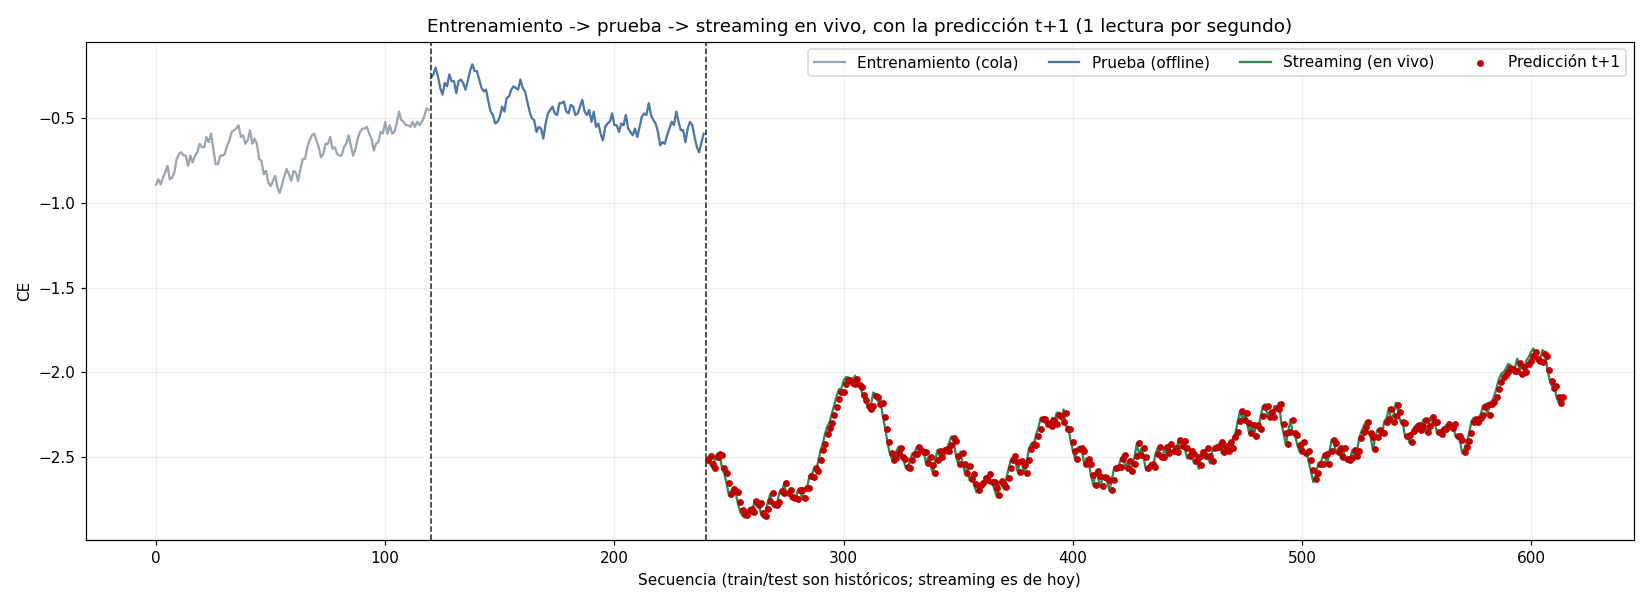

In [20]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "--root-user-action=ignore", "matplotlib"],
               check=False, capture_output=True)
import warnings
warnings.filterwarnings("ignore")
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

N_COLA = 120
cola_train = train.orderBy(F.desc("DateTime")).limit(N_COLA).orderBy("DateTime").select("CE").toPandas()
cola_test = test.orderBy(F.desc("DateTime")).limit(N_COLA).orderBy("DateTime").select("CE").toPandas()
stream_pd = stream_df.orderBy("fechaHora").toPandas()
n_train, n_test, n_stream = len(cola_train), len(cola_test), len(stream_pd)

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(range(n_train), cola_train["CE"], label="Entrenamiento (cola)", color="#9AA7B0")
ax.plot(range(n_train, n_train + n_test), cola_test["CE"], label="Prueba (offline)", color="#4C78A8")
x_stream = list(range(n_train + n_test, n_train + n_test + n_stream))
ax.plot(x_stream, stream_pd["CE"], label="Streaming (en vivo)", color="#2E8B57")
ax.scatter([x + 1 for x in x_stream], stream_pd["prediccionSiguienteCE"], color="#C00000", label="Predicción t+1", zorder=5, s=12)
ax.axvline(n_train, color="#222222", linestyle="--", linewidth=1)
ax.axvline(n_train + n_test, color="#222222", linestyle="--", linewidth=1)
ax.set_title("Entrenamiento -> prueba -> streaming en vivo, con la predicción t+1 (1 lectura por segundo)")
ax.set_xlabel("Secuencia (train/test son históricos; streaming es de hoy)")
ax.set_ylabel("CE")
ax.legend(ncol=4)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("/opt/artifacts/s10/grafico_train_test_stream.png", dpi=110)
plt.close(fig)
display(Image("/opt/artifacts/s10/grafico_train_test_stream.png"))

Los puntos rojos (predicción) van desplazados un paso a la derecha de su `CE` observado, alineados con el segundo que predicen, y siguen de cerca a la línea verde. El salto de nivel entre prueba y streaming no es un error del modelo: el productor arranca `CE` en el nivel de equilibrio de un clima inicial aleatorio, no continúa desde el último valor del histórico. La pregunta correcta es si el rojo sigue al verde, y lo hace.

## Resumen

| Paso | Evidencia |
|---|---|
| Dataset supervisado | `lead("CE", 1)` sobre `DateTime`, una fila menos que el Gold |
| División | 80/20 por posición, verificada cronológicamente |
| Baseline | Persistencia calculada antes de cualquier modelo |
| Modelos | `LinearRegression` y `RandomForestRegressor` comparados contra el baseline |
| Despliegue | `PipelineModel` (assembler + LR) guardado, recargado y con predicciones idénticas |
| Tiempo real | `foreachBatch` sobre Kafka, una lectura -> una predicción, sin ventanas ni estado |